# Question 2 — 23K-0004 | Kaggle | Early single-GPU initialization (v4)

Run from a **fresh Kaggle session** with T4 × 2 and Internet enabled. The first code cell hides the second GPU **before** PyTorch imports. Seven training runs and evaluation remain as in the previous notebook.


## Section 1 — exact theoretical answers

**(a)** LoRA parameters: `16*(4096+4096) = 131,072`. **(b)** Frozen layer parameters: `4096*4096 = 16,777,216`; adapter overhead `131072/16777216*100 = 0.78125%`.

**(c)** Set `B=0` and randomize `A` to make `BA=0` initially; the pretrained function is unchanged. At initialization `B` receives gradients while `A` initially has zero gradient. Making both random changes predictions before any training and risks unstable warmup (it would not make learning mathematically impossible).

**(d)** QLoRA reduces frozen base-memory via 4-bit **NF4** quantization, double quantization and paged optimizers; DoRA learns weight **magnitude** independently from low-rank updates to **direction**; AdaLoRA reallocates rank according to parameter importance instead of fixing an equal rank everywhere.

## 0. Install dependencies

In [1]:
# RUN THIS AS THE FIRST CODE CELL IN A FRESH KAGGLE SESSION.
# T4 x2 is enabled in Kaggle settings, but training uses only the first T4.
# This must execute before importing torch, transformers, or accelerate.
import os, sys
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
if "torch" in sys.modules:
    print("WARNING: PyTorch was already imported in this session.")
    print("Restart the Kaggle session/kernel once, then Run All from the beginning.")
else:
    print("Single-GPU visibility configured before PyTorch import.")


Single-GPU visibility configured before PyTorch import.


In [2]:
%pip -q install "transformers==4.57.3" "peft==0.17.1" "accelerate>=1.8,<2" "datasets>=3,<5" "bitsandbytes>=0.46,<0.50" "safetensors>=0.5" "pandas>=2" "matplotlib>=3"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [3]:
# IMPORTANT: Kaggle T4 x2 can cause Trainer to use torch.nn.DataParallel.
# Expose only ONE T4 before importing torch, so the quantized model and Trainer
# use the same CUDA device. Restart the Kaggle session before running this version.
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
import gc, re, json, math, time, random, shutil, hashlib, traceback
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_dataset, Dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, Trainer,
    TrainingArguments, TrainerCallback, set_seed)
from peft import LoraConfig, AdaLoraConfig, get_peft_model, prepare_model_for_kbit_training

STUDENT_ID = "23K-0004"
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DATASET_ID = "glaiveai/glaive-function-calling-v2"
SEED=42; EPOCHS=1; LR=5e-5; TRAIN_N=1800; TEST_N=200; TOTAL_N=TRAIN_N+TEST_N
MAX_LENGTH=2048  # Glaive tool schemas can be lengthy; NEVER truncate the gold target
MAX_NEW_TOKENS=160
CONFIG_VERSION="single_gpu_v4_early_cuda_visibility"
BATCH_SIZE=1; GRAD_ACCUM=8; TARGET_MODULES=['q_proj','v_proj']
ROOT = Path('/kaggle/working' if Path('/kaggle/working').exists() else '/mnt/data')/f'Assignment_Beta_Question_no_2_{STUDENT_ID}_results'
ROOT.mkdir(parents=True,exist_ok=True)
assert torch.cuda.is_available(), 'Enable GPU in Kaggle Notebook settings, then run again.'
assert torch.cuda.device_count() == 1, (
    f'PyTorch sees {torch.cuda.device_count()} GPUs. The first GPU-visibility cell was run too late. '
    'Restart the Kaggle session/kernel once, then Run All from the beginning.'
)
DEVICE = torch.device('cuda:0')
for k in range(torch.cuda.device_count()):
    p=torch.cuda.get_device_properties(k)
    print('GPU',k,p.name,round(p.total_memory/2**30,2),'GiB')
print('Using GPU 0 only | Torch',torch.__version__)
set_seed(SEED)
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
if tokenizer.pad_token_id is None: tokenizer.pad_token=tokenizer.eos_token

I0000 00:00:1794298051.792533      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


GPU 0 Tesla T4 14.56 GiB
Using GPU 0 only | Torch 2.11.0+cu130


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## 1. Download and parse real Glaive v2 examples

In [ ]:
import ast
DECODER=json.JSONDecoder()
def decode_glaive_call(payload):
    payload=payload.strip()
    for parser in (lambda x: DECODER.raw_decode(x)[0], ast.literal_eval):
        try:
            obj=parser(payload)
            if isinstance(obj,dict) and isinstance(obj.get('name'),str):
                arguments=obj.get('arguments',{})
                if isinstance(arguments,str):
                    try: arguments=json.loads(arguments)
                    except (json.JSONDecodeError,TypeError):
                        try: arguments=ast.literal_eval(arguments)
                        except (ValueError,SyntaxError): continue
                if isinstance(arguments,dict):
                    return {'name':obj['name'],'arguments':arguments}
        except (ValueError,SyntaxError,TypeError,json.JSONDecodeError):
            pass
    return None

def parse_glaive(row):
    chat=str(row.get('chat') or '')
    system=str(row.get('system') or '').strip()
    matches=list(re.finditer(r'<functioncall>\s*',chat,re.I))
    if not matches: return None
    # Prefer first valid call with an identifiable preceding customer request.
    for match in matches:
        # Stop before end-of-turn, preserving the literal call text.
        payload=re.split(r'<\|endoftext\|>|\bFUNCTION RESPONSE:',chat[match.end():],maxsplit=1,flags=re.I)[0].strip()
        call=decode_glaive_call(payload)
        if call is None: continue
        history=chat[:match.start()]
        users=list(re.finditer(r'\bUSER:\s*',history,re.I))
        if not users: continue
        question=history[users[-1].end():]
        question=re.split(r'\bASSISTANT:\s*|<\|endoftext\|>',question,maxsplit=1,flags=re.I)[0].strip()
        if not question or len(question)>3000: continue
        system=re.sub(r'^SYSTEM:\s*','',system,flags=re.I).strip()
        if not system or len(system)>10000: continue
        target=json.dumps(call,ensure_ascii=False,sort_keys=True,separators=(',',':'))
        return {'system':system,'message':question,'target_json':target}
    return None

# Validate the unusual Glaive format before downloading/processing 113k rows.
_example='{"name": "calculate_tip", "arguments": \'{"bill_amount": 50, "tip_percentage": 20}\'}'
assert decode_glaive_call(_example)=={'name':'calculate_tip','arguments':{'bill_amount':50,'tip_percentage':20}}
print('Glaive nested-arguments parser self-test: PASSED')

def prompt_for(rec):
    return tokenizer.apply_chat_template([
        {'role':'system','content':rec['system']+'\nWhen a tool is necessary, output exactly ONE JSON object with keys name and arguments. No prose or XML tags.'},
        {'role':'user','content':rec['message']}],tokenize=False,add_generation_prompt=True)

def encode_train(rec):
    p=tokenizer(prompt_for(rec),add_special_tokens=False)['input_ids']
    y=tokenizer(rec['target_json']+tokenizer.eos_token,add_special_tokens=False)['input_ids']
    if len(p)+len(y)>MAX_LENGTH: return None
    return {'input_ids':p+y,'attention_mask':[1]*(len(p)+len(y)),'labels':[-100]*len(p)+y}

DATAFILE=ROOT/'selected_glaive_2000.jsonl'
if DATAFILE.exists():
    chosen=[json.loads(x) for x in DATAFILE.read_text().splitlines() if x.strip()]
    assert len(chosen)==TOTAL_N, 'Saved dataset is incomplete; delete selected_glaive_2000.jsonl and rerun.'
    assert all(encode_train(r) is not None for r in chosen), 'Saved dataset exceeds current max_length; regenerate selection.'
    print('Using preserved original dataset selection:',DATAFILE)
else:
    print('Downloading full public dataset; this can take a few minutes on first run...')
    raw=load_dataset(DATASET_ID,split='train')
    assert {'system','chat'}.issubset(raw.column_names),f'Unexpected dataset columns: {raw.column_names}'
    order=np.random.default_rng(SEED).permutation(len(raw))
    chosen=[]; seen=set(); scanned=0
    rejection_counts={"no_parseable_function_call":0,"duplicate":0,"too_long":0}
    for idx in order:
        scanned+=1
        rec=parse_glaive(raw[int(idx)])
        if rec is None:
            rejection_counts["no_parseable_function_call"]+=1
            continue
        key=hashlib.sha256((rec['system']+'|'+rec['message']+'|'+rec['target_json']).encode()).hexdigest()
        if key in seen:
            rejection_counts["duplicate"]+=1
            continue
        if encode_train(rec) is None:
            rejection_counts["too_long"]+=1
            continue
        rec['glaive_row_index']=int(idx)
        chosen.append(rec); seen.add(key)
        if len(chosen)==TOTAL_N: break
    print("Dataset selection diagnostics:",rejection_counts, "scanned:",scanned, "selected:",len(chosen))
    assert len(chosen)==TOTAL_N, f"Only {len(chosen)} usable rows after {scanned} scans. Diagnostics: {rejection_counts}"
    with DATAFILE.open('w') as f:
        for rec in chosen:f.write(json.dumps(rec,ensure_ascii=False)+'\n')
    print('Scanned:',scanned,'| Selected genuine function calls:',len(chosen))

# Training/test split established once, before experiments. Reuse saved split on reruns.
SPLITFILE=ROOT/'split_indices.json'
if SPLITFILE.exists():
    split_idx=json.loads(SPLITFILE.read_text())
else:
    perm=np.random.default_rng(SEED).permutation(TOTAL_N).tolist()
    split_idx={'train':perm[:TRAIN_N],'test':perm[TRAIN_N:]}
    SPLITFILE.write_text(json.dumps(split_idx,indent=2))
train_rows=[chosen[i] for i in split_idx['train']]
test_rows=[chosen[i] for i in split_idx['test']]
assert len(train_rows)==1800 and len(test_rows)==200
assert set(split_idx['train']).isdisjoint(split_idx['test'])
train_ds=Dataset.from_list([encode_train(r) for r in train_rows])
def collate(batch):
    m=max(len(x['input_ids']) for x in batch); out={}
    for name,pad in [('input_ids',tokenizer.pad_token_id),('attention_mask',0),('labels',-100)]:
        out[name]=torch.tensor([x[name]+[pad]*(m-len(x[name])) for x in batch],dtype=torch.long)
    return out
meta={'student_id':STUDENT_ID,'model':MODEL_ID,'dataset':DATASET_ID,'seed':SEED,'n_train':1800,'n_test':200,
      'epochs':EPOCHS,'lr':LR,'config_version':CONFIG_VERSION,'target_modules':TARGET_MODULES,'max_length':MAX_LENGTH,
      'selection_rule':'first parseable functioncall and closest preceding user per Glaive chat',
      'limitations':'tool-call-only general Glaive subset; no no-tool cases; not four-function e-commerce benchmark'}
(ROOT/'methodology.json').write_text(json.dumps(meta,indent=2))
print('Train:',len(train_ds),'Held-out test:',len(test_rows),'maximum train tokens:',max(len(x['input_ids']) for x in train_ds))
print('Distinct function names:',len(set(json.loads(r['target_json'])['name'] for r in chosen)))
print('Example structure keys:',list(chosen[0].keys()))

Glaive nested-arguments parser self-test: PASSED


README.md:   0%|          | 0.00/106 [00:00<?, ?B/s]

glaive-function-calling-v2.json:   0%|          | 0.00/271M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/112960 [00:00<?, ? examples/s]

Dataset selection diagnostics: {'no_parseable_function_call': 2306, 'duplicate': 308, 'too_long': 0} scanned: 4614 selected: 2000
Scanned: 4614 | Selected genuine function calls: 2000
Train: 1800 Held-out test: 200 maximum train tokens: 523
Distinct function names: 217
Example structure keys: ['system', 'message', 'target_json', 'glaive_row_index']


## 2. Model loading, evaluation and training utilities

In [5]:
def cleanup():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def load_base(quant4=False,train=True):
    kw={'torch_dtype':torch.float32 if quant4 else torch.float16,'device_map':{'':'cuda:0'},'low_cpu_mem_usage':True, 'attn_implementation':'eager' if quant4 else 'sdpa'}
    if quant4:
        kw['quantization_config']=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
            bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=torch.float32)
    model=AutoModelForCausalLM.from_pretrained(MODEL_ID,**kw)
    model.config.use_cache=not train
    if train:
        if quant4:
            model=prepare_model_for_kbit_training(model,use_gradient_checkpointing=False)
        else: model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
    return model

def make_adapter(kind,rank,steps):
    shared=dict(target_modules=TARGET_MODULES,lora_alpha=16,lora_dropout=0.0,bias='none',task_type='CAUSAL_LM')
    if kind=='AdaLoRA':
        return AdaLoraConfig(init_r=12 if rank==8 else rank+4,target_r=rank,
            tinit=max(1,int(steps*.1)),tfinal=max(1,int(steps*.1)),deltaT=1,
            total_step=steps,orth_reg_weight=0.1,**shared)
    return LoraConfig(r=rank,use_dora=(kind=='DoRA'),**shared)

class AdaRankCallback(TrainerCallback):
    # Must run while gradients are available, before optimizer clears them.
    def __init__(self,model):self.model=model
    def on_pre_optimizer_step(self,args,state,control,**kwargs):
        self.model.base_model.update_and_allocate(min(state.global_step+1,self.model.peft_config['default'].total_step))
        return control

def training_args(path,kind):
    return TrainingArguments(output_dir=str(path),num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,gradient_accumulation_steps=GRAD_ACCUM,
        learning_rate=LR,lr_scheduler_type='linear',warmup_ratio=.05,weight_decay=0,
        optim='adamw_torch',fp16=(kind!='QLoRA'),bf16=False,max_grad_norm=0.5,
        logging_nan_inf_filter=False,logging_steps=1 if kind=='QLoRA' else 5,logging_first_step=True,save_strategy='no',
        report_to='none',remove_unused_columns=False,seed=SEED,data_seed=SEED,
        gradient_checkpointing=False,dataloader_num_workers=0,disable_tqdm=False)


class LossSafetyCallback(TrainerCallback):
    """Prevent a run with runaway loss from being recorded as successful."""
    def __init__(self, max_loss=100.0):
        self.max_loss=max_loss
        self.bad_loss=None
    def on_log(self,args,state,control,logs=None,**kwargs):
        if logs and 'loss' in logs:
            val=float(logs['loss'])
            if not math.isfinite(val) or val<=0 or val>self.max_loss:
                self.bad_loss=val
                control.should_training_stop=True
                print(f'UNSTABLE TRAINING: loss={val} at step {state.global_step}; run will NOT be accepted.')
        if logs and 'grad_norm' in logs:
            try:
                grad_norm=float(logs['grad_norm'])
                if not math.isfinite(grad_norm):
                    self.bad_loss=f'nonfinite grad_norm: {grad_norm}'
                    control.should_training_stop=True
                    print('UNSTABLE GRADIENT:',grad_norm,'at step',state.global_step)
            except (TypeError,ValueError):pass
        return control

def check_initial_loss(model):
    """Test a real training example before optimizer updates."""
    was_training=model.training
    model.eval()
    batch=collate([train_ds[0]])
    batch={k:v.to(DEVICE) for k,v in batch.items()}
    with torch.no_grad():
        output=model(**batch)
        loss=float(output.loss.detach().float().item())
    del output,batch
    if was_training:model.train()
    print('Loss before training:',round(loss,5))
    if not math.isfinite(loss) or loss>100:
        raise RuntimeError(f'Initial loss {loss} is abnormal. Check model/quantization/data; no optimizer step performed.')
    return loss

def check_backward_gradients(model):
    """Test one genuine supervised batch BEFORE the optimizer changes weights."""
    model.train()
    model.zero_grad(set_to_none=True)
    batch=collate([train_ds[0]])
    batch={k:v.to(DEVICE) for k,v in batch.items()}
    result=model(**batch)
    loss=result.loss
    print('Preflight train-mode loss:', float(loss.detach().float()))
    if not torch.isfinite(loss).item():
        raise RuntimeError('Nonfinite train-mode forward loss BEFORE backward')
    loss.backward()
    bad=[]; finite_count=0
    for name,p in model.named_parameters():
        if not p.requires_grad or p.grad is None: continue
        if not torch.isfinite(p.grad).all().item(): bad.append(name)
        else: finite_count+=1
    print('Preflight finite-gradient tensors:',finite_count,'| nonfinite:',len(bad))
    if bad:
        print('First nonfinite gradient parameters:',bad[:10])
        raise RuntimeError('Backward preflight failed BEFORE optimizer step; review listed parameters')
    if finite_count==0:
        raise RuntimeError('No trainable gradients found in backward preflight')
    model.zero_grad(set_to_none=True)
    del batch,result,loss
    torch.cuda.empty_cache()

def strict_score(raw,gold):
    try: obj=json.loads(raw)
    except (ValueError,TypeError):return (0,0,0,'broken JSON')
    expected=json.loads(gold)
    if not isinstance(obj,dict):return (1,0,0,'wrong JSON type')
    name=obj.get('name'); args=obj.get('arguments')
    correct_tool=int(name==expected['name'])
    full=int(correct_tool and isinstance(args,dict) and args==expected['arguments'] and set(obj)=={'name','arguments'})
    err='correct' if full else ('wrong tool' if not correct_tool else 'wrong/missing/extra argument')
    return (1,correct_tool,full,err)

@torch.inference_mode()
def evaluate(model,tag):
    model.eval(); model.config.use_cache=True
    observations=[]
    for j,row in enumerate(test_rows):
        x=tokenizer(prompt_for(row),return_tensors='pt',add_special_tokens=False).to(DEVICE)
        y=model.generate(**x,max_new_tokens=MAX_NEW_TOKENS,do_sample=False,
            pad_token_id=tokenizer.pad_token_id,eos_token_id=tokenizer.eos_token_id)
        response=tokenizer.decode(y[0,len(x['input_ids'][0]):],skip_special_tokens=True).strip()
        valid,acc,exact,error=strict_score(response,row['target_json'])
        observations.append({'glaive_row_index':row['glaive_row_index'],'message':row['message'],
            'expected':row['target_json'],'actual':response,'json_valid':valid,
            'tool_correct':acc,'full_match':exact,'error_type':error})
        if (j+1)%50==0:print(tag,'evaluated',j+1,'/ 200')
    df=pd.DataFrame(observations)
    df.to_csv(ROOT/f'{tag}_predictions.csv',index=False)
    return dict(json_valid_n=int(df.json_valid.sum()),json_valid_pct=float(100*df.json_valid.mean()),
        tool_accuracy_pct=float(100*df.tool_correct.mean()),full_match_pct=float(100*df.full_match.mean()))

RESULTS_FILE=ROOT/'results_all_methods.csv'
results=pd.read_csv(RESULTS_FILE).to_dict('records') if RESULTS_FILE.exists() else []
def save_record(rec):
    global results
    results=[r for r in results if not (r['method']==rec['method'] and int(r['rank'])==int(rec['rank']))]
    results.append(rec)
    pd.DataFrame(results).to_csv(RESULTS_FILE,index=False)
    display(pd.DataFrame([rec]))

def run_method(kind,rank=8):
    assert kind in ('LoRA','QLoRA','DoRA','AdaLoRA')
    tag=f'{kind}_r{rank}'; path=ROOT/tag; record_file=ROOT/f'{tag}_metrics.json'
    if record_file.exists():
        rec=json.loads(record_file.read_text())
        if rec.get('config_version')==CONFIG_VERSION:
            print('Already complete; skipping',tag)
            return rec
        print('Old run uses different configuration; retraining for fair comparison:',tag)

    cleanup();set_seed(SEED)
    torch.cuda.reset_peak_memory_stats(DEVICE)
    m=None; trainer=None
    try:
        m=load_base(quant4=(kind=='QLoRA'),train=True)
        nsteps=math.ceil(len(train_ds)/(BATCH_SIZE*GRAD_ACCUM))*EPOCHS
        m=get_peft_model(m,make_adapter(kind,rank,nsteps))
        trainable=sum(x.numel() for x in m.parameters() if x.requires_grad)
        total=sum(x.numel() for x in m.parameters())
        initial_loss=check_initial_loss(m)
        if kind=='QLoRA':check_backward_gradients(m)
        safety=LossSafetyCallback()
        callbacks=[safety] + ([AdaRankCallback(m)] if kind=='AdaLoRA' else [])
        trainer=Trainer(model=m,args=training_args(path,kind),train_dataset=train_ds,
            data_collator=collate,callbacks=callbacks)
        print('Trainer n_gpu:', trainer.args.n_gpu,'| world_size:',trainer.args.world_size)
        assert trainer.args.n_gpu == 1 and trainer.args.world_size == 1, 'Single-GPU training required for this benchmark'
        start=time.perf_counter()
        train_output=trainer.train()
        if safety.bad_loss is not None:
            raise RuntimeError(f'Unstable loss ({safety.bad_loss}); invalid training run — inspect precision and data.')
        if trainer.state.global_step < nsteps:
            raise RuntimeError(f'Training ended early: {trainer.state.global_step}/{nsteps} steps')
        torch.cuda.synchronize(DEVICE)
        mins=(time.perf_counter()-start)/60
        peak=torch.cuda.max_memory_allocated(DEVICE)/2**30
        m.save_pretrained(path/'adapter')
        metrics=evaluate(m,tag)
        rec={'method':kind,'rank':rank,'trainable_params':trainable,
            'trainable_pct':100*trainable/total,'peak_training_GiB':peak,
            'train_minutes':mins,'initial_loss':initial_loss,
            'config_version':CONFIG_VERSION,**metrics,'status':'completed'}
        record_file.write_text(json.dumps(rec,indent=2))
        return rec
    finally:
        del trainer,m
        cleanup()

def run_and_save(kind,rank=8):
    try:rec=run_method(kind,rank)
    except Exception as e:
        traceback.print_exc()
        rec={'method':kind,'rank':rank,'status':f'FAILED: {type(e).__name__}: {e}'}
    save_record(rec)
    return rec

## 3. Baseline and four rank-8 runs

In [6]:
if any(r['method']=='Baseline' and r.get('status')=='completed' for r in results):
    print('Skipping completed baseline')
else:
    cleanup()
    model=load_base(train=False)
    try:
        met=evaluate(model,'Baseline')
        save_record({'method':'Baseline','rank':0,'trainable_params':0,'trainable_pct':0.0,
            'peak_training_GiB':None,'train_minutes':None,**met,'status':'completed'})
    finally:
        del model;cleanup()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Baseline evaluated 50 / 200
Baseline evaluated 100 / 200
Baseline evaluated 150 / 200
Baseline evaluated 200 / 200


,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct,status
0,Baseline,0,0,0.0,None,None,193,96.5,96.0,88.5,completed


In [7]:
# The original unstable QLoRA metrics will not be reused.
run_and_save('QLoRA',8)

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Loss before training: 0.91128
Preflight train-mode loss: 0.9112808108329773
Preflight finite-gradient tensors: 112 | nonfinite: 0
Trainer n_gpu: 1 | world_size: 1


Step,Training Loss
1,0.965800
2,1.149200
3,1.131500
4,1.348500
5,1.322600
6,1.106700
7,1.341600
8,1.002600
9,1.278600
10,0.839900


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


QLoRA_r8 evaluated 50 / 200
QLoRA_r8 evaluated 100 / 200
QLoRA_r8 evaluated 150 / 200
QLoRA_r8 evaluated 200 / 200


,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,initial_loss,config_version,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct,status
0,QLoRA,8,1089536,0.12246,4.745631,17.838035,0.911281,single_gpu_v4_early_cuda_visibility,200,100.0,100.0,88.0,completed


{'method': 'QLoRA',
 'rank': 8,
 'trainable_params': 1089536,
 'trainable_pct': 0.12246023063727084,
 'peak_training_GiB': 4.745631217956543,
 'train_minutes': 17.838034546916667,
 'initial_loss': 0.9112808108329773,
 'config_version': 'single_gpu_v4_early_cuda_visibility',
 'json_valid_n': 200,
 'json_valid_pct': 100.0,
 'tool_accuracy_pct': 100.0,
 'full_match_pct': 88.0,
 'status': 'completed'}

In [8]:
run_and_save('LoRA',8)

The model is already on multiple devices. Skipping the move to device specified in `args`.


Loss before training: 0.91628
Trainer n_gpu: 1 | world_size: 1


Step,Training Loss
1,1.122300
5,1.494800
10,1.408200
15,1.154900
20,0.653200
25,0.499100
30,0.326000
35,0.249500
40,0.232100
45,0.128900


LoRA_r8 evaluated 50 / 200
LoRA_r8 evaluated 100 / 200
LoRA_r8 evaluated 150 / 200
LoRA_r8 evaluated 200 / 200


,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,initial_loss,config_version,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct,status
0,LoRA,8,1089536,0.070529,3.852,8.166207,0.916285,single_gpu_v4_early_cuda_visibility,200,100.0,100.0,88.5,completed


{'method': 'LoRA',
 'rank': 8,
 'trainable_params': 1089536,
 'trainable_pct': 0.07052908413277896,
 'peak_training_GiB': 3.8519997596740723,
 'train_minutes': 8.166207129449996,
 'initial_loss': 0.9162848591804504,
 'config_version': 'single_gpu_v4_early_cuda_visibility',
 'json_valid_n': 200,
 'json_valid_pct': 100.0,
 'tool_accuracy_pct': 100.0,
 'full_match_pct': 88.5,
 'status': 'completed'}

In [9]:
run_and_save('DoRA',8)

The model is already on multiple devices. Skipping the move to device specified in `args`.


Loss before training: 0.91716
Trainer n_gpu: 1 | world_size: 1


Step,Training Loss
1,1.123600
5,1.486600
10,1.384800
15,1.121400
20,0.610800
25,0.471100
30,0.307800
35,0.234800
40,0.220900
45,0.122200


DoRA_r8 evaluated 50 / 200
DoRA_r8 evaluated 100 / 200
DoRA_r8 evaluated 150 / 200
DoRA_r8 evaluated 200 / 200


,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,initial_loss,config_version,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct,status
0,DoRA,8,1139712,0.073775,3.852361,10.440958,0.917159,single_gpu_v4_early_cuda_visibility,200,100.0,100.0,89.5,completed


{'method': 'DoRA',
 'rank': 8,
 'trainable_params': 1139712,
 'trainable_pct': 0.07377473781962839,
 'peak_training_GiB': 3.8523612022399902,
 'train_minutes': 10.440957848500004,
 'initial_loss': 0.9171594381332397,
 'config_version': 'single_gpu_v4_early_cuda_visibility',
 'json_valid_n': 200,
 'json_valid_pct': 100.0,
 'tool_accuracy_pct': 100.0,
 'full_match_pct': 89.5,
 'status': 'completed'}

In [10]:
run_and_save('AdaLoRA',8)

The model is already on multiple devices. Skipping the move to device specified in `args`.


Loss before training: 1.09548
Trainer n_gpu: 1 | world_size: 1


Step,Training Loss
1,2.555800
5,2.931800
10,2.944100
15,2.918600
20,2.834000
25,2.731200
30,2.814000
35,2.865600
40,2.724500
45,2.626300


AdaLoRA_r8 evaluated 50 / 200
AdaLoRA_r8 evaluated 100 / 200
AdaLoRA_r8 evaluated 150 / 200
AdaLoRA_r8 evaluated 200 / 200


,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,initial_loss,config_version,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct,status
0,AdaLoRA,8,1634976,0.1058,3.884298,10.479139,1.095477,single_gpu_v4_early_cuda_visibility,194,97.0,96.5,89.0,completed


{'method': 'AdaLoRA',
 'rank': 8,
 'trainable_params': 1634976,
 'trainable_pct': 0.10579976720551683,
 'peak_training_GiB': 3.8842978477478027,
 'train_minutes': 10.479138584466675,
 'initial_loss': 1.095476746559143,
 'config_version': 'single_gpu_v4_early_cuda_visibility',
 'json_valid_n': 194,
 'json_valid_pct': 97.0,
 'tool_accuracy_pct': 96.5,
 'full_match_pct': 89.0,
 'status': 'completed'}

## 4. Pick the winner and repeat with ranks 4, 16 and 32

Winning method: DoRA


The model is already on multiple devices. Skipping the move to device specified in `args`.


Loss before training: 0.91716
Trainer n_gpu: 1 | world_size: 1


Step,Training Loss
1,1.123600
5,1.487100
10,1.383900
15,1.117800
20,0.615300
25,0.482800
30,0.318400
35,0.250400
40,0.234400
45,0.132800


DoRA_r4 evaluated 50 / 200
DoRA_r4 evaluated 100 / 200
DoRA_r4 evaluated 150 / 200
DoRA_r4 evaluated 200 / 200


,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,initial_loss,config_version,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct,status
0,DoRA,4,594944,0.038525,3.844244,10.446058,0.917159,single_gpu_v4_early_cuda_visibility,200,100.0,100.0,89.0,completed


... (6 outputs left out)

Loss before training: 0.91716
Trainer n_gpu: 1 | world_size: 1


Step,Training Loss
1,1.123600
5,1.487300
10,1.388000
15,1.124800
20,0.614000
25,0.475000
30,0.311300
35,0.237900
40,0.221300
45,0.122700


DoRA_r32 evaluated 50 / 200
DoRA_r32 evaluated 100 / 200
DoRA_r32 evaluated 150 / 200
DoRA_r32 evaluated 200 / 200


,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,initial_loss,config_version,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct,status
0,DoRA,32,4408320,0.284753,3.901067,10.620594,0.917159,single_gpu_v4_early_cuda_visibility,200,100.0,100.0,88.5,completed


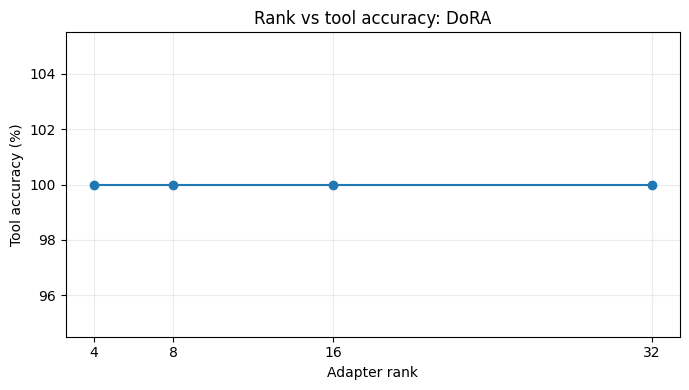

,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct,status,initial_loss,config_version
5,DoRA,4,594944,0.038525,3.844244,10.446058,200,100.0,100.0,89.0,completed,0.917159,single_gpu_v4_early_cuda_visibility
3,DoRA,8,1139712,0.073775,3.852361,10.440958,200,100.0,100.0,89.5,completed,0.917159,single_gpu_v4_early_cuda_visibility
6,DoRA,16,2229248,0.144200,3.868597,10.641583,200,100.0,100.0,88.5,completed,0.917159,single_gpu_v4_early_cuda_visibility
7,DoRA,32,4408320,0.284753,3.901067,10.620594,200,100.0,100.0,88.5,completed,0.917159,single_gpu_v4_early_cuda_visibility


In [11]:
r=pd.DataFrame(results)
need={'LoRA','QLoRA','DoRA','AdaLoRA'}
ok=r[(r['method'].isin(need)) & (r['rank']==8) & (r['status']=='completed')].copy()
if len(ok)!=4:
    raise RuntimeError(f'Four successful rank-8 runs required; got {ok.method.tolist()}. Review failures above.')
winning=ok.sort_values(['full_match_pct','tool_accuracy_pct','peak_training_GiB'],ascending=[False,False,True]).iloc[0]['method']
print('Winning method:',winning)
for rank in (4,16,32):
    response=run_and_save(winning,rank)
    if response.get('status')!='completed':raise RuntimeError(f'Rank {rank} failed: resolve issue before plotting.')
rank_df=pd.DataFrame(results)
rank_df=rank_df[(rank_df.method==winning)&(rank_df['rank'].isin([4,8,16,32]))&(rank_df.status=='completed')].sort_values('rank')
assert len(rank_df)==4
rank_df.to_csv(ROOT/'rank_study.csv',index=False)
plt.figure(figsize=(7,4));plt.plot(rank_df['rank'],rank_df['tool_accuracy_pct'],marker='o')
plt.xticks([4,8,16,32]);plt.xlabel('Adapter rank');plt.ylabel('Tool accuracy (%)')
plt.title(f'Rank vs tool accuracy: {winning}');plt.grid(alpha=.25);plt.tight_layout()
plt.savefig(ROOT/'rank_vs_tool_accuracy.png',dpi=160);plt.show()
display(rank_df)

## 5. Automatically assemble report draft + five observed errors

In [12]:
tab=pd.DataFrame(results)
complete=tab[tab.status=='completed'].copy()
complete.to_csv(ROOT/'completed_results.csv',index=False)
summary_cols=['method','rank','trainable_params','trainable_pct','peak_training_GiB','train_minutes',
              'json_valid_n','json_valid_pct','tool_accuracy_pct','full_match_pct']
print('Measured comparison:')
display(complete[[c for c in summary_cols if c in complete.columns]])

if 'winning' in globals():
    path=ROOT/f'{winning}_r8_predictions.csv'
    errors=pd.read_csv(path)
    errors=errors[errors.full_match==0].head(5)
    errors.to_csv(ROOT/'five_best_model_failures.csv',index=False)
    best=complete[(complete.method==winning)&(complete['rank']==8)].iloc[0]
    best_rank=rank_df.sort_values('full_match_pct',ascending=False).iloc[0]
    failures='\n\n'.join(f"{i+1}. **Message:** {x.message}\n   **Expected:** `{x.expected}`\n   **Actual:** `{x.actual}`\n   **Error:** {x.error_type}" for i,x in enumerate(errors.itertuples()))
    if not failures: failures='No errors on the held-out set; do not fabricate examples.'
    report=f"""# Q2 short report — 23K-0004 (measured draft)

## Production decision
Rank-8 winner (by predeclared exact-match / tool-accuracy / memory rule): **{winning}**. Measured full match **{best.full_match_pct:.1f}%**, tool accuracy **{best.tool_accuracy_pct:.1f}%**, JSON validity **{best.json_valid_pct:.1f}%**, peak training memory **{best.peak_training_GiB:.2f} GiB**, training **{best.train_minutes:.1f} min**. Inference speed was not measured; do not claim the method has the fastest serving latency. These are general Glaive function-calling results, not a live e-commerce authorization test.

## Rank sensitivity
The highest rank-study exact-match score was at **r={int(best_rank['rank'])}**, with **{best_rank.full_match_pct:.1f}%** full match and **{best_rank.tool_accuracy_pct:.1f}%** tool accuracy. Inspect the chart to decide if extra rank meaningfully helps; rank-8 winner is not automatically the best rank for deployment.

## Five real errors from the best rank-8 method
{failures}

## Multi-agent adapter design
A shared frozen base can serve a router, shipping, and refund agent with separately loaded lightweight LoRA adapters, avoiding three independently trained full models. One risk is an adapter switch during a concurrent request, which may cause the wrong agent behavior/tool policy; bind a per-request adapter or isolate routing contexts.

## Surprising result and limitations
Use the actual table and chart to write a specific surprising observation. In particular, general Glaive tool-call-only evaluation does not assess no-tool abstention or unauthorized refunds. Before deployment, add a separate four-tool e-commerce benchmark and backend permission checks; JSON validation alone does not authorize financial actions.

## AI-use declaration
ChatGPT assisted with notebook code, Glaive parsing and explanation. Hugging Face datasets/transformers/PEFT provided the data and training infrastructure. All metrics must come from the recorded Kaggle GPU runs.
"""
    (ROOT/'Q2_report_draft.md').write_text(report)
    print('Wrote report draft and five-failure CSV')
else:print('Report draft skipped: not all four methods are completed.')

Measured comparison:


,method,rank,trainable_params,trainable_pct,peak_training_GiB,train_minutes,json_valid_n,json_valid_pct,tool_accuracy_pct,full_match_pct
0,Baseline,0,0,0.000000,NaN,NaN,193,96.5,96.0,88.5
1,QLoRA,8,1089536,0.122460,4.745631,17.838035,200,100.0,100.0,88.0
2,LoRA,8,1089536,0.070529,3.852000,8.166207,200,100.0,100.0,88.5
3,DoRA,8,1139712,0.073775,3.852361,10.440958,200,100.0,100.0,89.5
4,AdaLoRA,8,1634976,0.105800,3.884298,10.479139,194,97.0,96.5,89.0
5,DoRA,4,594944,0.038525,3.844244,10.446058,200,100.0,100.0,89.0
6,DoRA,16,2229248,0.144200,3.868597,10.641583,200,100.0,100.0,88.5
7,DoRA,32,4408320,0.284753,3.901067,10.620594,200,100.0,100.0,88.5


Wrote report draft and five-failure CSV


## 6. Export everything — always run after experiments

In [13]:
archive=shutil.make_archive(str(ROOT),'zip',root_dir=ROOT.parent,base_dir=ROOT.name)
print('Export:',archive)
print('Size:',round(Path(archive).stat().st_size/2**20,1),'MiB')
print('Saved files:',len(list(ROOT.rglob('*'))))

Export: /kaggle/working/Assignment_Beta_Question_no_2_23K-0004_results.zip
Size: 43.2 MiB
Saved files: 59
